# Домашнє завдання №1 — аналітика (задача I, варіант V5)

## 0. Налаштування

In [1]:
import copy
import math
import os
import platform
import random
import sys
from pathlib import Path
from IPython.display import display
import time
import tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from general import Student, load_students
DATA_PATH = Path("data/students.csv")
from app1 import Approach1Naive
from app2 import Approach2bisect
from app3 import Approach3LazyCache

APPROACHES = {
    "1: наївний": Approach1Naive,
    "2: відсортований масив": Approach2bisect,
    "3: ліниве кешування": Approach3LazyCache,
}

WEIGHTS = (100, 5, 100)

RESULTS_PATH = Path("results/benchmark_results.csv")
FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Вступ і методологія

Задача V5: топ-100 студентів за рейтингом, зміна рейтингу за email, групи з найбільшим середнім. Співвідношення операцій - 100:5:100, маємо 200 операцій ситання до 5 операцій зміни.
Обрані підходи:
1. динамічний масив без індексів, усе рахується повним проходом;
2. постійно відсортований динамічний масив з бінарним пошуком + хеш-таблиці;
3. хеш-таблиці + кеш результатів з застаріванням, топ-100 через бінарну купу на вимогу (lazy).
Середовище виконання - Python.
Пропускна здатність, час операцій і пам'ять вимірювалися у функіціях run_one і run_all_experiments.

run_one:
Ми створюємо об’єкт класу підходу, який нам наданий. Ми вимірюємо найбільшу кількість пам’яті в момент, коли ми створюємо цей об’єкт. Ми робимо це з допомогою tracemalloc: це така класна річ, яка не враховує сторонню пам’ять процесора використану на код, а тільки ту що для алгоритму треба була. Далі ми ДО початку вимірювання часу створюємо набір з випадкової послідовності команд у співвідношення 100:5:100 в кількості 100000, щоб потім запускати ці команди для вимірювання.

Далі: в нас підхід 3 лускає 100000 операцій за лічені секунди і мілісекунди, тому нам треба більше даних. але генерувати мільйон чи й більше операцій ми не хочемо, тому ми його ЗАЦИКЛЮЄМО. Як тільки індекс доходить кінця, ми починаємо все з початку: обнуляємо індекс, і той починає іти заново. Кожні 100 операцій ми перевіряємо чи не пройшло вже 10 секунд. Це рішення далося мені методом спроб і помилок: виявилося що перевіряти щоразу дуже надлишково, оскільки якщо умовний третій підхід робить кожну операцію надзвичайно швидко, то вимірювання часу може зайняти просто більше часу, це в рази зменшує наші показники ефективності. А перевіряти кожну 1000ну операцію погано, бо підхід 1 працює на 1000 операціях довше ніж 10 секунд, це завищує статистику в його сторону. 
Також, є така штука як lap: оскільки ми робимо ці 100000 операцій однаковими, то якщо ми умовно однією з цих операцій змінюємо рейтинг студенту номер 42, то в наступних в нього вже буде цей змінений рейтинг і ми просто будемо виконувати менше операцій. Тому ми додаємо якусь константу lap, яка відносно проста бо ми домножили її на 0.37, тому коли ми будемо додавати по одиниці до неї і округлювати по модулю 100, в нас не станеться такого що в нас lap буде кратний 100 і в нас знову буде скіпатись ця операція.
далі ми просто встановлюємо скільки часу пройшло в сумі і робимо висновок про середню тривалість операції через середнє арифметичне.

run_all_experiments:
ми читаємо дані з файлу який нам наданий. ми перемішуємо їх, бо вони посортовані по групах і оцінках, а коли ми будемо робити вибірку менеш ста тисяч, ми просто будемо брати верхні 100, 1000 і так далі студентів, то вони мають бути різними. 
Далі ми ітеруємось по підходах, і для кожного робимо 5 вимірів для точнішого результату вимірів (беремо середнє арифметичне). Кожного разу як ми запускаємо вимір, ми робимо глибоку копію масиву студентів, бо наприклад підхід 2 їх сортує, то щоб підхід після нього отримав початковий список студентів з незміненими рейтингами. 

Після того як ми зробили виміри, ми запихаємо дані в пандас таблицю і рахуємо найкращого по кількості операцій підхода. Після цього ми запускаємо для лідера по пропускній здатності додаткові тести для масштабування, щоб зообразити це на графіках.

## 2. Перевірка коректності (автотести)

**Ідея.** Для кожного підходу порівнюємо відповіді з **еталоном** — дуже простим кодом, який щоразу рахує все з нуля й живе у власній копії даних. Якщо підхід збігається з еталоном на всіх тестах, то й підходи між собою збігаються.

Що перевіряється:

| Тест | Навіщо |
|---|---|
| `fewer_than_100` | студентів менше 100: `top100` має повернути всіх |
| `equal_ratings` | багато однакових рейтингів: порядок у межах рівних не важливий, але рейтинги й склад мають бути коректні |
| `same_rating_update` | зміна рейтингу на той самий |
| `unknown_email` | неіснуючий email → `False`, дані не змінюються |
| `all_groups_equal_average` | групи з математично однаковим середнім, але різними похибками округлення float |
| `all_ratings_equal` | у всіх однаковий рейтинг → усі групи найкращі |
| `ranking_moves` | студент піднімається/опускається в топі, змінюється найкраща група |
| `returns_are_copies` | зміна повернутого списку не ламає внутрішній стан (захист від ненадійного користувача) |
| `random_*` | випадкові послідовності операцій у профілі навантаження та з багатьма оновленнями |

In [2]:
GROUP_COUNT_MAX = 100


def group_name(g):
    return f"A{chr(65 + g // 26)}{chr(65 + g % 26)}-{g % GROUP_COUNT_MAX:02d}"


def mk(email, group, rating):
    """Студент із заповненими 'зайвими' полями."""
    return Student("Тест","Тест", email,2000, 1, 1,group, rating, "38(050)00-00-000",)


def make_students(n, n_groups, seed, decimals=1):
    rng = random.Random(seed)
    return [
        mk(f"user{i}@student.org", group_name(rng.randrange(n_groups)),
           round(rng.uniform(0, 100), decimals))
        for i in range(n)
    ]


class Oracle:
    """Еталон: повільний, але очевидно правильний. Усе рахує з нуля.
    Для середнього використовує math.fsum (точна сума без накопичення похибки)."""

    def __init__(self, students):
        self.rating = {s.m_email: s.m_rating for s in students}
        self.group = {s.m_email: s.m_group for s in students}

    def change_rate(self, email, new_rating):
        if email not in self.rating:
            return False
        self.rating[email] = new_rating
        return True

    def top100_ratings(self):
        return sorted(self.rating.values(), reverse=True)[:100]

    def best_groups(self):
        buckets = {}
        for email, r in self.rating.items():
            buckets.setdefault(self.group[email], []).append(r)
        avgs = {g: math.fsum(v) / len(v) for g, v in buckets.items()}
        best = max(avgs.values())
        return sorted(g for g, a in avgs.items() if best - a < 1e-9)


def check_top100(result, oracle):
    """Повертає текст помилки або None."""
    got = [s.m_rating for s in result]
    expected = oracle.top100_ratings()
    if got != expected:
        return f"рейтинги топ-100 відрізняються (отримано {got[:3]}..., очікувалось {expected[:3]}...)"
    emails = [s.m_email for s in result]
    if len(set(emails)) != len(emails):
        return "у топ-100 є дублікати студентів"
    for s in result:
        if oracle.rating.get(s.m_email) != s.m_rating:
            return f"студент {s.m_email} має застарілий рейтинг у відповіді"
    return None


def check_state(db, oracle):
    """Звіряє обидві операції читання з еталоном."""
    problems = []
    err = check_top100(db.top100(), oracle)
    if err:
        problems.append("top100: " + err)
    got, expected = db.best_groups(), oracle.best_groups()
    if got != expected:
        problems.append(f"best_groups: отримано {got}, очікувалось {expected}")
    return problems


def fresh(cls, students):
    """Кожен підхід отримує ВЛАСНУ копію студентів: change_rate змінює об'єкти на місці."""
    return cls(copy.deepcopy(students))

In [3]:
def test_fewer_than_100(cls):
    students = [mk(f"s{i}@student.org", "AAA-01" if i % 2 else "BBB-01", float(i * 7 % 50)) for i in range(12)]
    return check_state(fresh(cls, students), Oracle(students))


def test_equal_ratings(cls):
    rng = random.Random(1)
    students = [mk(f"s{i}@student.org", group_name(rng.randrange(8)), float(rng.choice([10, 20, 30]))) for i in range(150)]
    oracle, db = Oracle(students), fresh(cls, students)
    problems = check_state(db, oracle)
    for _ in range(30):
        e, r = rng.choice(students).m_email, float(rng.choice([10, 20, 30, 40]))
        db.change_rate(e, r)
        oracle.change_rate(e, r)
        problems += check_state(db, oracle)
    return problems[:3]


def test_same_rating_update(cls):
    students = make_students(150, 10, seed=2)
    oracle, db = Oracle(students), fresh(cls, students)
    target = students[7]
    if db.change_rate(target.m_email, target.m_rating) is not True:
        return ["change_rate на те саме значення має повертати True"]
    return check_state(db, oracle)


def test_unknown_email(cls):
    students = make_students(150, 10, seed=3)
    oracle, db = Oracle(students), fresh(cls, students)
    if db.change_rate("nobody@student.org", 99.0) is not False:
        return ["неіснуючий email має повертати False"]
    return check_state(db, oracle)


def test_all_groups_equal_average(cls):
    # Однаковий набір рейтингів у різному порядку: у float суми можуть відрізнятися на ~1e-16.
    students = [
        mk("a1@student.org", "AAA-01", 0.1), mk("a2@student.org", "AAA-01", 0.2), mk("a3@student.org", "AAA-01", 0.3),
        mk("b1@student.org", "BBB-01", 0.3), mk("b2@student.org", "BBB-01", 0.2), mk("b3@student.org", "BBB-01", 0.1),
        mk("c1@student.org", "CCC-01", 0.2), mk("c2@student.org", "CCC-01", 0.3), mk("c3@student.org", "CCC-01", 0.1),
    ]
    return check_state(fresh(cls, students), Oracle(students))


def test_all_ratings_equal(cls):
    students = [mk(f"s{i}@student.org", group_name(i % 5), 42.5) for i in range(120)]
    return check_state(fresh(cls, students), Oracle(students))


def test_ranking_moves(cls):
    students = make_students(150, 10, seed=4)
    oracle, db = Oracle(students), fresh(cls, students)
    problems = []
    # найслабший стає найкращим
    weakest = min(students, key=lambda s: s.m_rating)
    db.change_rate(weakest.m_email, 100.0); oracle.change_rate(weakest.m_email, 100.0)
    problems += check_state(db, oracle)
    # найкращий опускається на дно
    strongest = max(students, key=lambda s: oracle.rating[s.m_email])
    db.change_rate(strongest.m_email, 0.0); oracle.change_rate(strongest.m_email, 0.0)
    problems += check_state(db, oracle)
    # уся найкраща група отримує 0 -> лідер групи змінюється
    leader = oracle.best_groups()[0]
    for s in students:
        if oracle.group[s.m_email] == leader:
            db.change_rate(s.m_email, 0.0); oracle.change_rate(s.m_email, 0.0)
    problems += check_state(db, oracle)
    return problems[:3]


def test_returns_are_copies(cls):
    students = make_students(150, 10, seed=5)
    oracle, db = Oracle(students), fresh(cls, students)
    top = db.top100(); top.clear()          # "користувач" псує отриманий список
    best = db.best_groups(); best.append("HACK")
    return check_state(db, oracle)


def make_ops(students, n_ops, weights, seed):
    rng = random.Random(seed)
    emails = [s.m_email for s in students]
    ops = []
    for _ in range(n_ops):
        kind = rng.choices(["top100", "change_rate", "best_groups"], weights=weights)[0]
        ops.append((kind, rng.choice(emails), round(rng.uniform(0, 100), 1)) if kind == "change_rate" else (kind,))
    return ops


def run_random(cls, weights, seed, decimals):
    students = make_students(300, 25, seed=seed, decimals=decimals)
    oracle, db = Oracle(students), fresh(cls, students)
    for i, op in enumerate(make_ops(students, 3000, weights, seed)):
        if op[0] == "top100":
            err = check_top100(db.top100(), oracle)
            if err:
                return [f"операція #{i} top100: {err}"]
        elif op[0] == "best_groups":
            got, expected = db.best_groups(), oracle.best_groups()
            if got != expected:
                return [f"операція #{i} best_groups: {got} != {expected}"]
        else:
            if db.change_rate(op[1], op[2]) is not True:
                return [f"операція #{i} change_rate мала повернути True"]
            oracle.change_rate(op[1], op[2])
    return []


def test_random_workload(cls):
    return run_random(cls, WEIGHTS, seed=10, decimals=1)


def test_random_update_heavy(cls):
    return run_random(cls, (1, 3, 1), seed=11, decimals=0)  # цілі рейтинги -> багато рівних


TESTS = {
    "fewer_than_100": test_fewer_than_100,
    "equal_ratings": test_equal_ratings,
    "same_rating_update": test_same_rating_update,
    "unknown_email": test_unknown_email,
    "all_groups_equal_average": test_all_groups_equal_average,
    "all_ratings_equal": test_all_ratings_equal,
    "ranking_moves": test_ranking_moves,
    "returns_are_copies": test_returns_are_copies,
    "random_workload": test_random_workload,
    "random_update_heavy": test_random_update_heavy,
}


def run_all_tests():
    table, details = {}, []
    for tname, tfn in TESTS.items():
        table[tname] = {}
        for aname, cls in APPROACHES.items():
            try:
                problems = tfn(cls)
            except Exception as exc:  # помилка в самому підході теж є провалом тесту
                problems = [f"виняток {type(exc).__name__}: {exc}"]
            table[tname][aname] = "✅" if not problems else "❌"
            for p in problems[:2]:
                details.append(f"[{aname}] {tname}: {p}")
    return pd.DataFrame(table).T, details


test_table, test_details = run_all_tests()
display(test_table)
print("\n".join(test_details) if test_details else "Усі тести пройдено.")

,1: наївний,2: відсортований масив,3: ліниве кешування
fewer_than_100,✅,✅,✅
equal_ratings,✅,✅,✅
same_rating_update,✅,✅,✅
unknown_email,✅,✅,✅
all_groups_equal_average,✅,✅,✅
all_ratings_equal,✅,✅,✅
ranking_moves,✅,✅,✅
returns_are_copies,✅,✅,✅
random_workload,✅,✅,✅
random_update_heavy,✅,✅,✅


Усі тести пройдено.


**Висновок про коректність**

Всі тести пройшли, єдине, що було не так - це порівняння float через "==": тест "all_groups_equal_average" показував три хреста. Виявилося, що оскільки патон написаний на основі асемблера, то в цього теж при постійній зміні довгих дробових (ще й часто не раціональних) чисел і при їхньому порівнянні накописується похибка, через що порівнювати середні груп через пряме порівняння не можна, а тільки через abs(avg-max_avg)<=1e-9

## 3. Вимірювання 

Результати записуються в CSV `results/benchmark_results.csv`, один рядок - один запуск одного підходу на одному розмірі.

| колонка | що це |
|---|---|
| `approach` | назва підходу, **точно** як ключ у `APPROACHES` |
| `n` | розмір бази (кількість студентів) |
| `repeat` | номер повторення (1, 2, 3, ...) |
| `ops_done` | скільки операцій виконано за час вимірювання |
| `duration_s` | скільки секунд тривало вимірювання (10 для основного експерименту) |
| `lat_top100_us` | середній час одного виклику `top100` у цьому запуску, мікросекунди |
| `lat_change_rate_us` | те саме для `change_rate` |
| `lat_best_groups_us` | те саме для `best_groups` |
| `memory_mb` | пам'ять структури, мегабайти (методику вибираєш і обґрунтовуєш сама) |

**Функції:**

- run_one: усі 3 підходи на одному великому розмірі (наприклад n = 100 000), 10 секунд, ≥5 повторів;
- run_all_experiments: для найкращого підходу 10 різних розмірів від 100 до 100 000, ≥5 повторів на точку.

In [4]:
def run_one(approach_cls, students, repeat, duration_s=10.0):
    """Один запуск одного підходу.
    Повертає dict із ключами: approach, n, repeat, ops_done, duration_s,
    lat_top100_us, lat_change_rate_us, lat_best_groups_us, memory_mb.
    """
    n=len(students)
    approach_name = next(name for name,cls in APPROACHES.items() if cls==approach_cls)

    tracemalloc.start()
    db = approach_cls(students)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    memory_mb = peak/(1024*1024)
    rng = random.Random(42 + repeat)
    emails = [s.m_email for s in students]

    base_plan = []
    for _ in range(100000):
        op = rng.choices([0, 1, 2], weights=WEIGHTS)[0]
        if op == 0:
            base_plan.append((0,))
        elif op == 1:
            base_plan.append((1, rng.choice(emails), rng.uniform(0.0, 100.0)))
        elif op == 2:
            base_plan.append((2,))

    plan_length = len(base_plan)
    idx = 0
    lap = 0

    time_top100 = 0.0
    time_change = 0.0
    time_best = 0.0
    count_top100 = 0
    count_change = 0
    count_best = 0

    global_start = time.perf_counter()
    keep_running = True
    batch_size = 100
    while keep_running:
        for _ in range(batch_size):
            op_data = base_plan[idx]
            idx += 1
            if idx == plan_length:
                idx = 0
                lap += 1
            op = op_data[0]
            if op == 0:
                op_start = time.perf_counter()
                db.top100()
                time_top100 += (time.perf_counter() - op_start)
                count_top100 += 1
            elif op == 1:
                new_rating = (op_data[2] + lap * 0.37) % 100.0
                op_start = time.perf_counter()
                db.change_rate(op_data[1], new_rating)
                time_change += (time.perf_counter() - op_start)
                count_change += 1
            elif op == 2:
                op_start = time.perf_counter()
                db.best_groups()
                time_best += (time.perf_counter() - op_start)
                count_best += 1
        if time.perf_counter() - global_start >= duration_s:
            keep_running = False
    elapsed_time = time.perf_counter() - global_start

    lat_top100_us = (time_top100/count_top100*1_000_000) if count_top100 > 0 else 0.0
    lat_change_us = (time_change/count_change*1_000_000) if count_change > 0 else 0.0
    lat_best_us = (time_best/count_best*1_000_000) if count_best > 0 else 0.0

    return {
        "approach": approach_name,
        "n": n,
        "repeat": repeat,
        "ops_done": count_top100+count_change+count_best,
        "duration_s": elapsed_time,
        "lat_top100_us": lat_top100_us,
        "lat_change_rate_us": lat_change_us,
        "lat_best_groups_us": lat_best_us,
        "memory_mb": memory_mb}

def run_all_experiments():
    """Цикли по підходах/розмірах/повтореннях.
    Повертає pandas.DataFrame із колонками з таблиці вище."""
    results = []

    N_MAIN = 100000
    REPEATS = 5
    DURATION = 10.0
    all_students = load_students(DATA_PATH)
    random.Random(42).shuffle(all_students)
    N_MAIN = min(len(all_students), 100000)
    all_students = all_students[:N_MAIN]

    for approach_name, approach_cls in APPROACHES.items():
        for rep in range(1, REPEATS + 1):
            fresh_students = copy.deepcopy(all_students)

            res = run_one(approach_cls, fresh_students, rep, DURATION)
            results.append(res)
    current_df = pd.DataFrame(results)
    current_df["rate"] = current_df["ops_done"]/current_df["duration_s"]

    best_approach_name = current_df[current_df.n == N_MAIN].groupby("approach")["rate"].mean().idxmax()
    best_approach_cls = APPROACHES[best_approach_name]
    sizes = [100, 300, 1000, 3000, 10000, 20000, 40000, 60000, 80000, 100000]
    for n in sizes:
        if n == N_MAIN:
            continue

        print(f"  Тестуємо розмір N = {n}...")
        for rep in range(1, REPEATS + 1):
            fresh_students = copy.deepcopy(all_students[:n])

            res = run_one(best_approach_cls, fresh_students, rep, DURATION)
            results.append(res)

    print("Вимірювання звершено")
    return pd.DataFrame(results)

In [5]:
df_new = run_all_experiments()
RESULTS_PATH.parent.mkdir(exist_ok=True)
df_new.to_csv(RESULTS_PATH, index=False)

  Тестуємо розмір N = 100...
  Тестуємо розмір N = 300...
  Тестуємо розмір N = 1000...
  Тестуємо розмір N = 3000...
  Тестуємо розмір N = 10000...
  Тестуємо розмір N = 20000...
  Тестуємо розмір N = 40000...
  Тестуємо розмір N = 60000...
  Тестуємо розмір N = 80000...
Вимірювання звершено


## 4. Завантаження результатів 

In [6]:
def make_demo_results(path, seed=0):
    rng = np.random.default_rng(seed)
    sizes = np.unique(np.round(np.logspace(2, 5, 10)).astype(int))
    lg = lambda n: np.log2(n)
    # вигадані моделі: (top100, change_rate, best_groups) у мкс
    model = {
        "1: наївний": (lambda n: 0.024 * n * lg(n), lambda n: 0.05 * n, lambda n: 0.25 * n),
        "2: відсортований масив": (lambda n: 2 + 0 * n, lambda n: 0.006 * n + 10, lambda n: 0.03 * n),
        "3: ліниве кешування": (lambda n: 1 + 0.08 * n / 20, lambda n: 1.5 + 0 * n, lambda n: 1 + 0.04 * n / 20),
    }
    mem = {"1: наївний": 8, "2: відсортований масив": 110, "3: ліниве кешування": 80}
    rows = []
    for a, (ft, fc, fb) in model.items():
        for n in sizes:
            for rep in range(1, 6):
                noise = lambda: rng.lognormal(0, 0.04)
                t, c, b = ft(n) * noise(), fc(n) * noise(), fb(n) * noise()
                avg = (WEIGHTS[0] * t + WEIGHTS[1] * c + WEIGHTS[2] * b) / sum(WEIGHTS)
                rows.append(dict(approach=a, n=int(n), repeat=rep, ops_done=int(10e6 / avg), duration_s=10.0,
                                 lat_top100_us=t, lat_change_rate_us=c, lat_best_groups_us=b,
                                 memory_mb=mem[a] * n / 1e6 * noise()))
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(path, index=False)

TAG = "  [ФЕЙКОВІ ДАНІ]" if "demo" in RESULTS_PATH.name else ""

OP_COLS = {"top100": "lat_top100_us", "change_rate": "lat_change_rate_us", "best_groups": "lat_best_groups_us"}
REQUIRED = ["approach", "n", "repeat", "ops_done", "duration_s", *OP_COLS.values(), "memory_mb"]

if not RESULTS_PATH.exists():
    raise FileNotFoundError(f"Немає файлу {RESULTS_PATH}. Спочатку виконай розділ 3 і збережи результати.")

df = pd.read_csv(RESULTS_PATH)
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"У файлі бракує колонок: {missing}"
df["ops_per_10s"] = df["ops_done"] / df["duration_s"] * 10  # нормуємо до 10 секунд

order = [a for a in APPROACHES if a in df["approach"].unique()]
COLORS = dict(zip(order, ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]))

# основний розмір для порівняння підходів = найбільший n, на якому є ВСІ підходи
common_n = set.intersection(*[set(df[df.approach == a].n) for a in order])
N_MAIN = max(common_n)

# Перевірки відповідності вимогам завдання
reps = df.groupby(["approach", "n"]).size()
if reps.min() < 5:
    print("⚠️ Є точки, де менше 5 повторень:", reps[reps < 5].to_dict())
print(f"Рядків: {len(df)}; підходи: {order}; N_MAIN = {N_MAIN}")
print("Розміри для кожного підходу:", {a: sorted(df[df.approach == a].n.unique().tolist()) for a in order})

Рядків: 60; підходи: ['1: наївний', '2: відсортований масив', '3: ліниве кешування']; N_MAIN = 100000
Розміри для кожного підходу: {'1: наївний': [100000], '2: відсортований масив': [100000], '3: ліниве кешування': [100, 300, 1000, 3000, 10000, 20000, 40000, 60000, 80000, 100000]}


## 5. Графіки 

In [7]:
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


def stats(data, value_col, by=("approach", "n")):
    """Середнє, середньоквадратичне відхилення (вибіркове, ddof=1) і кількість повторень."""
    out = data.groupby(list(by))[value_col].agg(["mean", "std", "count"]).reset_index()
    out["std"] = out["std"].fillna(0.0)
    return out


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200)
    plt.show()


def fmt(x):
    return f"{x:,.0f}".replace(",", " ")


def plot_throughput_bar(data, n):
    s = stats(data[data.n == n], "ops_per_10s").set_index("approach").loc[order]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(s.index, s["mean"], yerr=s["std"], capsize=5, color=[COLORS[a] for a in s.index])
    for rect, m in zip(bars, s["mean"]):
        ax.annotate(fmt(m), (rect.get_x() + rect.get_width() / 2, m), ha="center", va="bottom",
                    xytext=(0, 4), textcoords="offset points")
    if s["mean"].max() / s["mean"].min() > 30:
        ax.set_yscale("log")
    ax.set_ylabel("операцій за 10 с")
    ax.set_title(f"Пропускна здатність, n = {fmt(n)}{TAG}")
    save_fig("1_throughput_bar")


def plot_latency_bars(data, n):
    sub = data[data.n == n]
    x = np.arange(len(OP_COLS))
    w = 0.8 / len(order)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, a in enumerate(order):
        d = sub[sub.approach == a]
        means = [d[c].mean() for c in OP_COLS.values()]
        stds = [d[c].std(ddof=1) if len(d) > 1 else 0.0 for c in OP_COLS.values()]
        ax.bar(x + (i - (len(order) - 1) / 2) * w, means, w, yerr=stds, capsize=3, label=a, color=COLORS[a])
    ax.set_xticks(x)
    ax.set_xticklabels(list(OP_COLS))
    ax.set_yscale("log")
    ax.set_ylabel("середній час виклику, мкс (лог. шкала)")
    ax.set_title(f"Час окремих операцій, n = {fmt(n)}{TAG}")
    ax.legend()
    save_fig("2_latency_bars")


def plot_memory_bars(data, n):
    s = stats(data[data.n == n], "memory_mb").set_index("approach").loc[order]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(s.index, s["mean"], yerr=s["std"], capsize=5, color=[COLORS[a] for a in s.index])
    for rect, m in zip(bars, s["mean"]):
        ax.annotate(f"{m:.1f}", (rect.get_x() + rect.get_width() / 2, m), ha="center", va="bottom",
                    xytext=(0, 4), textcoords="offset points")
    ax.set_ylabel("пам'ять, МБ")
    ax.set_title(f"Використання пам'яті, n = {fmt(n)}{TAG}")
    save_fig("3_memory_bars")


def plot_scaling_lines(data, value_col, ylabel, title, name, approaches):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for a in approaches:
        s = stats(data[data.approach == a], value_col)
        ax.errorbar(s["n"], s["mean"], yerr=s["std"], marker="o", capsize=3, label=a, color=COLORS[a])
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n — кількість студентів (лог. шкала)")
    ax.set_ylabel(ylabel)
    ax.set_title(title + TAG)
    ax.legend()
    save_fig(name)


def best_approach(data, n):
    return stats(data[data.n == n], "ops_per_10s").set_index("approach")["mean"].idxmax()

### 5.1 Пропускна здатність — стовпчаста діаграма (bar chart) із похибками

Висота стовпчика — середня кількість операцій за 10 с по повтореннях, "вуса" — середньоквадратичне відхилення. Якщо різниця між підходами більша за 30 разів, вісь Y автоматично стає логарифмічною.

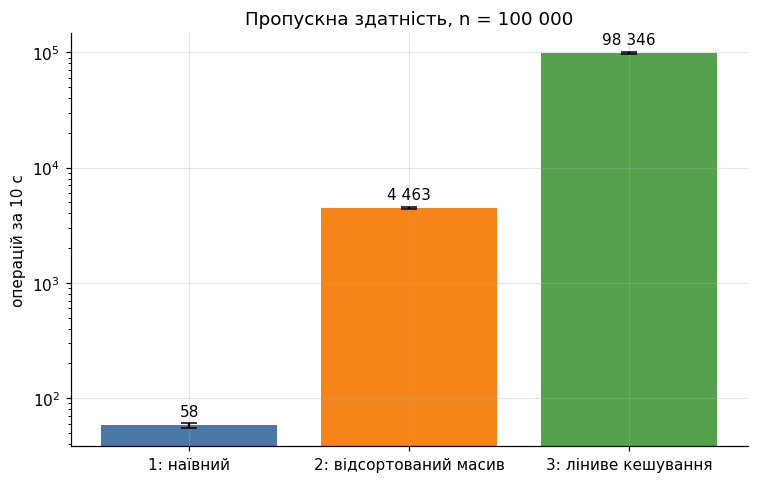

In [8]:
plot_throughput_bar(df, N_MAIN)

**Аналіз**

Найбільше операцій виконав підхід 3%: приблизно у 18 разів більше ніж підхід 2, і приблизно у 1500 більше ніж перший. Так відбулося в тому числі через наше співвідношення 100:5:100, де дві 100 це операції читання, і тільки 5 - зміни. Наші 2 останні підходи спеціалізуються на тому, щоб читання конкретно топу груп і студентів було якнайшвидшим, для цього там спеціально розоблені структури даних, а підхід 1 - наївний, там швидко працює операція зміни, але дуже повільно - читання.

### 5.2 Час окремих операцій — згрупована стовпчаста діаграма, логарифмічна вісь Y

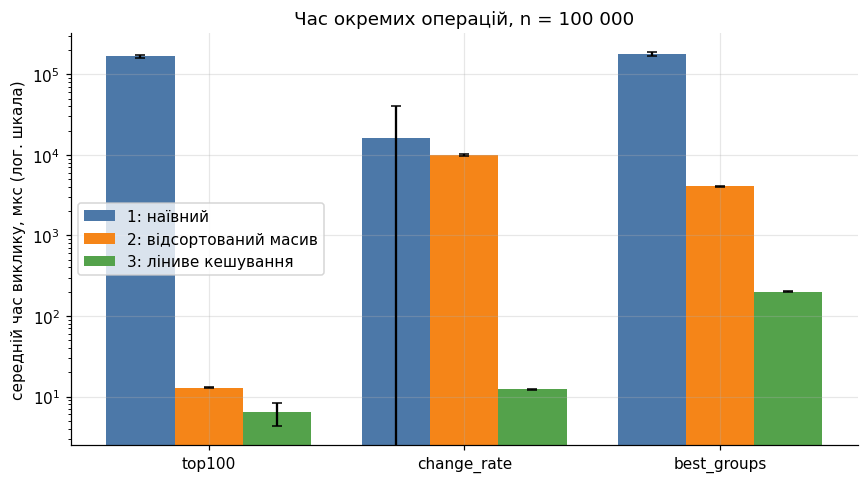

In [9]:
plot_latency_bars(df, N_MAIN)

**Аналіз **

| Операція | Наївний (Підхід 1) | Словники (Підхід 2) | Ліниве кешування (Підхід 3) |
| :--- | :--- | :--- | :--- |
| **`change_rate`** (Запис) | $O(N)$ | $O(1)$ | $O(1)$ |
| **`top100`** (Читання) | $O(N \log N)$ | $O(N \log N)$ | $O(1)$ (амортизована)* |
| **`best_groups`** (Читання) | $O(N)$ | $O(N)$ | $O(1)$ (амортизована)* |

*\*У найгіршому випадку (відразу після запису) перше читання в лінивому кешуванні коштуватиме $O(N \log N)$, але всі наступні тисячі читань — $O(1)$.*

1. наївний підхід, change_rate. оновлення вимагає повного проходу по списку для пошуку потрібного студента. тому складність O(N)
O(N) для бази 100000 дорівнює 100000 операцій, на графіку час становить близько 10000 мікросекунд.
результат: збіглося, залежність лінійна.   
2. наївний підхід, top100. при кожному запиті весь масив сортується з нуля, складність функції сортування в пайтоні це O(N log N). O(N log N) дорівнює 100000 * 16.6, що дає близько 1.6 мільйона операцій, на графіку це найповільніша дія біля 200000 мікросекунд.
результат: збіглося.   
3. наївний підхід, best_groups.алгоритм лінійно перебирає всіх студентів для групування і підрахунку середнього балу, тому складність O(N). O(N) дорівнює 100000 операцій, на графіку час понад 100000 мікросекунд.
результат: збіглося.   
4. підхід 2, change_rate. очікувався запис у хеш-таблицю за константний час, але швидкість на графіку вказує на зсув елементів для підтримки відсортованого масиву. за таблицею очікувалось O(1) тобто 1 операція, але графік показує близько 10000 мікросекунд.
результат: не збіглося з таблицею, фактична складність виявилась O(N)  
5. підхід 2, top100. за таблицею мало бути сортування, але графік показує швидке взяття перших 100 елементів з уже підготовленого масиву. очікувалось O(N log N) тобто 1.6 мільйона операцій, але на графіку час склав лише близько 10 мікросекунд, бо масив сортується не завжди.
результат: не збіглося, на практиці алгоритм спрацював миттєво як O(1).   
6. підхід 2, best_groups. для агрегації груп доводиться проходитись по всіх студентах., тому час лінійний. O(N) дорівнює 100000 операцій, на графіку час зменшився до 4000 мікросекунд, але порядок зберігся.
результат: збіглося, залежність лінійна.   
7. ліниве кешування, change_rate. запис лише змінює оцінку і ставить прапорець недійсності, не перераховуючи весь рейтинг. O(1) дорівнює 1 базовій операції, на графіку час становить близько 10 мікросекунд.
результат: збіглося, працює миттєво.   
8. ліниве кешування, top100.при великій кількості читань алгоритм повертає готовий масив із пам'яті. амортизована складність O(1) дорівнює 1 операції, на графіку час найменший і становить близько 5 мікросекунд.
результат: збіглося.   
9. ліниве кешування, best_groups. так само як і топ, вже згруповані дані повертаються з кешу без повторних обчислень. амортизована складність O(1) дорівнює 1 операції, на графіку час впав до 200 мікросекунд.
результат: збіглося.  

### 5.3 Пам'ять — стовпчаста діаграма

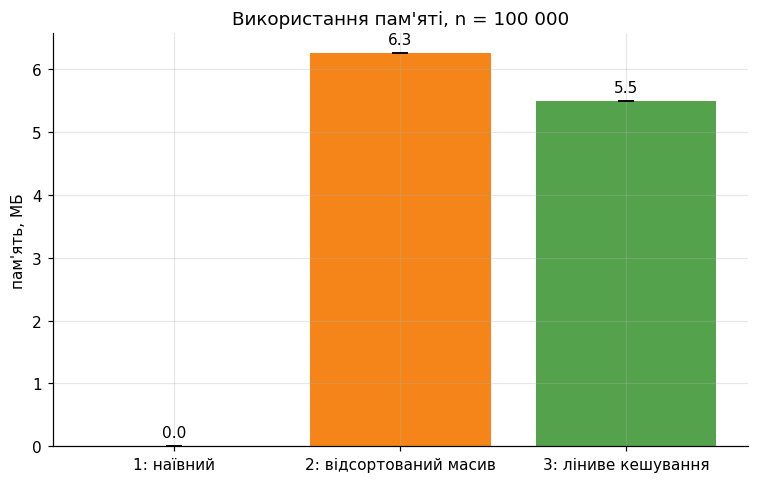

In [10]:
plot_memory_bars(df, N_MAIN)

**Аналіз**

Я вибрала методику tracemalloc: це функція, яка не враховує сторонню пам’ять процесора використану на код, а тільки ту що для алгоритму треба була. Найменше па'мяті використовує наївний підхід: в нього тільки 1 масив, і ми його не сортуємо і ніде не зберігаєо. Найбільше у відсортованому масиві, бо там весь відсортований масив, а в третьому підході тише топ 100.

## 6. Лінійна регресія для найповільнішої операції 

In [13]:
BASIS = {
    "n·log₂n": lambda n: n * np.log2(n),
    "n":       lambda n: n,
    "1":       lambda n: np.ones_like(n, dtype=float),
}

# Найповільніша операція найкращого підходу — за середнім часом на найбільшому n.
largest_n = best_df.n.max()
slowest_op = max(OP_COLS, key=lambda op: best_df[best_df.n == largest_n][OP_COLS[op]].mean())
print(f"Підхід: {BEST}; найповільніша операція на n={fmt(largest_n)}: {slowest_op}")
y_col = OP_COLS[slowest_op]


def design_matrix(n, basis):
    n = np.asarray(n, dtype=float)
    return np.column_stack([f(n) for f in basis.values()])


def fit_least_squares(n, y, basis):
    X = design_matrix(n, basis)
    scale = np.abs(X).max(axis=0)                 # масштабуємо стовпці для стійкості обчислень
    coef_scaled, *_ = np.linalg.lstsq(X / scale, y, rcond=None)
    coef = coef_scaled / scale
    resid = y - X @ coef
    r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return coef, r2


coef, r2 = fit_least_squares(best_df["n"].to_numpy(), best_df[y_col].to_numpy(), BASIS)

coef_table = pd.DataFrame({"fᵢ(n)": list(BASIS), "cᵢ": coef})
display(coef_table)
print(f"R² = {r2:.4f}")
print("T(n) = " + " + ".join(f"{c:.4g}·{name}" for c, name in zip(coef, BASIS)) + "   [мкс]")
if (coef < 0).any():
    print("⚠️ Є від'ємні коефіцієнти — перегляньте вибір fᵢ(n) (див. пояснення вище).")

Підхід: 3: ліниве кешування; найповільніша операція на n=100 000: best_groups


,fᵢ(n),cᵢ
0,n·log₂n,-0.002750
1,n,0.047135
2,1,23.435600


R² = 0.8818
T(n) = -0.00275·n·log₂n + 0.04714·n + 23.44·1   [мкс]
⚠️ Є від'ємні коефіцієнти — перегляньте вибір fᵢ(n) (див. пояснення вище).


,n,"середнє, мкс","σ, мкс",повторів,T(n) модель,"відхилення, %"
0,100,2.740,0.115,5,26.322,-860.783
1,300,7.940,0.080,5,30.787,-287.750
2,1000,27.917,1.008,5,43.164,-54.615
3,3000,94.013,1.273,5,69.543,26.029
4,10000,185.804,4.907,5,129.358,30.379
5,20000,201.014,3.154,5,180.277,10.316
6,40000,203.519,4.321,5,227.113,-11.593
7,60000,202.071,5.331,5,232.428,-15.023
8,80000,193.801,4.250,5,210.780,-8.761
9,100000,200.035,4.275,5,169.081,15.474


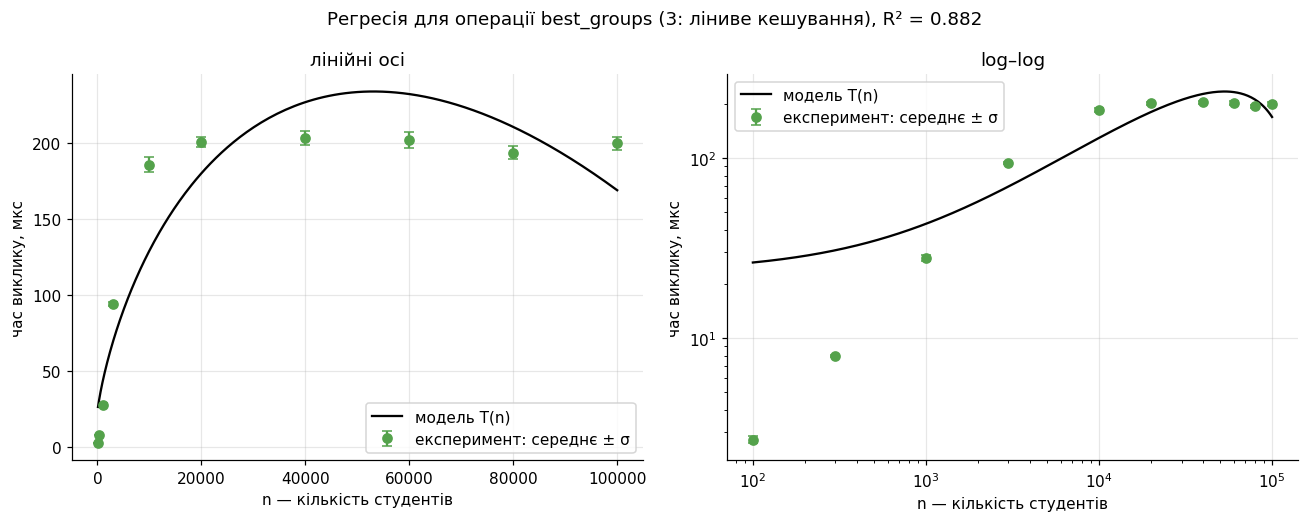

In [14]:
# Таблиця: експериментальні точки (середнє, σ) і значення моделі
pts = stats(best_df, y_col)
pts["T(n) модель"] = design_matrix(pts["n"], BASIS) @ coef
pts["відхилення, %"] = (pts["mean"] - pts["T(n) модель"]) / pts["mean"] * 100
pts = pts.rename(columns={"mean": "середнє, мкс", "std": "σ, мкс", "count": "повторів"}).drop(columns="approach")
display(pts.round(3))

# Графік: точки з похибками + крива моделі (лінійні та логарифмічні осі)
grid = np.logspace(np.log10(pts["n"].min()), np.log10(pts["n"].max()), 300)
curve = design_matrix(grid, BASIS) @ coef

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, log in zip(axes, (False, True)):
    ax.errorbar(pts["n"], pts["середнє, мкс"], yerr=pts["σ, мкс"], fmt="o", capsize=3,
                label="експеримент: середнє ± σ", color=COLORS[BEST])
    ax.plot(grid, curve, "-", color="black", label="модель T(n)")
    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n — кількість студентів")
    ax.set_ylabel("час виклику, мкс")
    ax.set_title(("log–log" if log else "лінійні осі") + TAG)
    ax.legend()
fig.suptitle(f"Регресія для операції {slowest_op} ({BEST}), R² = {r2:.3f}")
save_fig("7_regression")

**Аналіз регресії**

Базисні функції $f_1(n) = n \log n$, $f_2(n) = n$, $f_3(n) = 1$ обрані на основі теоретичної складності компонентів алгоритму.   Функція $n \log n$ відповідає за операції сортування або роботу з пірамідою (наприклад, heapq.nlargest).   Функція $n$ описує лінійний прохід по базі, який потрібен для групування студентів та підрахунку середнього балу у методі best_groups.   Функція $1$ є константою, що відображає базові накладні витрати (overhead) на виклик функцій та ініціалізацію змінних.

## 7. Висновки

- Який підхід оптимальний: Для співвідношення 100:5:100 (операції читання значно переважають над операціями запису) лідером є Ліниве кешування. Графіки пропускної здатності та часу операцій показують, що він дозволяє виконувати читання за амортизований час $O(1)$, зводячи затримки до мінімуму.
- Чи підтвердилась теорія складності: Так. Графіки масштабування на логарифмічній шкалі наочно доводять, що наївний алгоритм деградує лінійно $O(N)$, тоді як швидкість читання у лінивому кешуванні залишається константною (горизонтальна лінія на графіку), а пам'ять зростає лінійно.
- Обмеження експерименту: Тестування проводилося в наблжених до ідеалу умовах: функція tracemalloc, випадкові дані замість реальних патернів поведінки користувачів, та перевірка лише одного фіксованого співвідношення операцій читання/запису.
- Захист від DoS (ненадiйний користувач): зловмисник може чергувати одну операцію запису і одну операцію читання рейтингу top100. Це змусить алгоритм при кожному читанні перераховувати кеш з нуля за $O(N \log N)$, що призведе до крашу. Щоб захиститися від цього, треба відмовитися від лінивого кешування на користь структур даних із гарантованою логарифмічною складністю (Red-Black Tree, AVL-дерево).